## Playground for first biophython code

Trying code from the biopython.org website

In [4]:
from Bio.Seq import Seq
my_seq = Seq("AGTACACTGGT")
print(my_seq)
print(my_seq.complement())
print(my_seq.reverse_complement())

AGTACACTGGT
TCATGTGACCA
ACCAGTGTACT


trying out working with fasta files, downloaded sequence for Dsup from UniProt and got a first look at it (lengh matches literature)

In [6]:
from Bio import SeqIO
for seq_record in SeqIO.parse("../data/raw_data/01_dsup_ramva.fasta", "fasta"):
    print(seq_record.id)
    print(repr(seq_record.seq))
    print(len(seq_record))
    print(seq_record.count("R"))
    print(seq_record.count("K"))
    print(seq_record.count("D"))
    print(seq_record.count("E"))

P0DOW4:
Seq('MASTHQSSTEPSSTGKSEETKKDASQGSGQDSKNVTVTKGTGSSATSAAIVKTG...KRK')
445
12
59
29
19


counting amino acids

In [7]:
from Bio import SeqIO
from Bio.SeqUtils.ProtParam import ProteinAnalysis
for seq_record in SeqIO.parse("../data/raw_data/01_dsup_ramva.fasta", "fasta"):
    analysis = ProteinAnalysis(str(seq_record.seq))
    print(analysis.count_amino_acids())

{'A': 72, 'C': 0, 'D': 29, 'E': 19, 'F': 2, 'G': 69, 'H': 5, 'I': 4, 'K': 59, 'L': 1, 'M': 3, 'N': 6, 'P': 14, 'Q': 18, 'R': 12, 'S': 79, 'T': 31, 'V': 21, 'W': 0, 'Y': 1}


figuring out whether or not I can calculate the total charge of this protein

In [ ]:
from Bio import SeqIO
from Bio.SeqUtils.ProtParam import ProteinAnalysis

seq_dsup_ramva = SeqIO.read("../data/raw_data/01_dsup_ramva.fasta", "fasta")
analyse = ProteinAnalysis(str(seq_dsup_ramva))

print(analyse.charge_at_pH(7.0))   # does not look like the literature value (+23 as a total net charge) or what I calculated per hand (+27), probably need a more specific method like looking at the relative charge of different sections ect
print(analyse.isoelectric_point())

-5.134707248936115
4.818662071228027


trying matplot

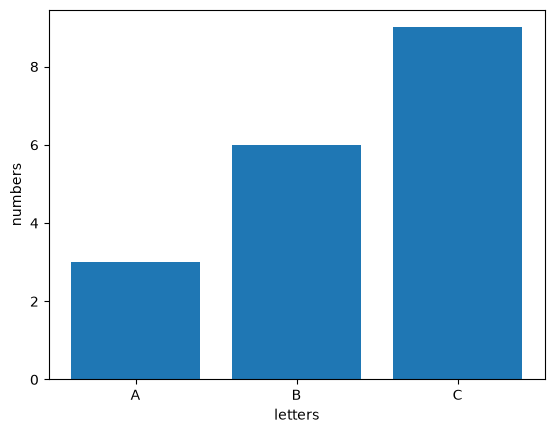

In [15]:
import matplotlib.pyplot as plt
n1 = ["A", "B", "C"]
n2 = [3, 6, 9]

plt.bar(n1, n2)

plt.xlabel("letters") 
plt.ylabel("numbers")

plt.show()

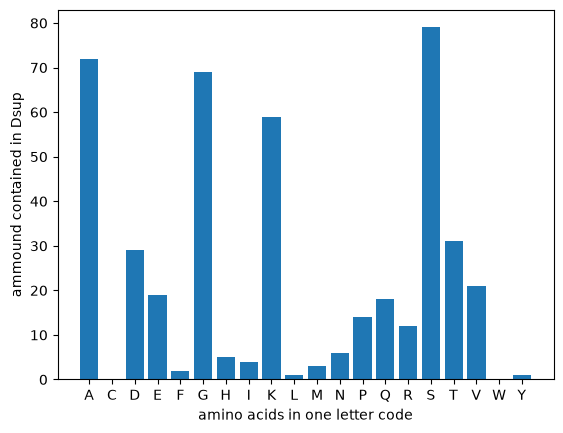

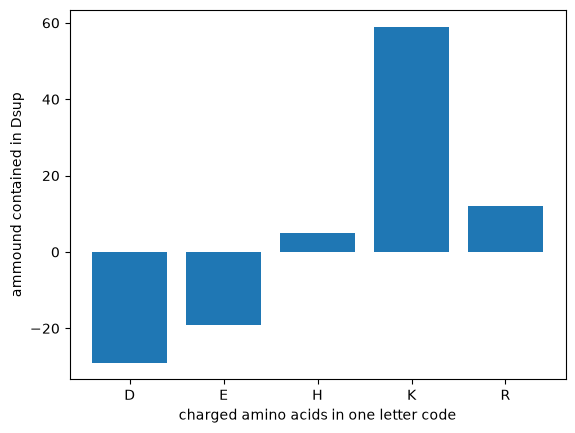

net charge of dsup: 28


In [ ]:
import matplotlib.pyplot as plt

all_AS = ["A", "C", "D", "E", "F", "G", "H", "I", "K", "L", "M", "N", "P", "Q", "R", "S", "T", "V", "W", "Y"]
amount_AS = [72, 0, 29, 19, 2, 69, 5, 4, 59, 1, 3, 6, 14, 18, 12, 79, 31, 21, 0, 1]

plt.bar(all_AS, amount_AS)
plt.xlabel("amino acids in one letter code")
plt.ylabel("ammound contained in Dsup")
plt.show()

charged_AS = ["D", "E", "H", "K", "R"]
amount_cAS = [-29, -19, 5, 59, 12]

plt.bar(charged_AS, amount_cAS)
plt.xlabel("charged amino acids in one letter code")
plt.ylabel("ammound contained in Dsup")
plt.show()

netcharge = -29 + (-19) + 5 + 59 + 12  # ignore histidin since its at pH 7 mostly neutral charged?
print("net charge of dsup:", netcharge)

[0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 1, 0, -1, -1, 0, 1, 1, -1, 0, 0, 0, 0, 0, 0, 0, -1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, -1, 0, 1, 0, 0, 0, 0, -1, 0, 1, -1, 1, 0, 1, 0, 0, 0, 1, -1, 0, 0, 0, 0, 0, -1, 0, 1, 0, 0, 0, -1, 0, 1, 0, 0, 0, -1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, -1, 0, 0, 1, 0, 0, 0, -1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, -1, 0, 0, 0, 0, 0, 1, -1, 0, 0, 0, 1, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, -1, 1, 0, -1, -1, 1, 1, -1, 0, -1, 0, 0, 0, -1, 1, 1, -1, -1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 1, 1, 0, -1, 0, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, -1, 0, 0, 1, 0, 0, -1, 0, 0, 0, 0, -1, 0, -1, 0, 0, -1, 0, 0, 0, 1, 0, 0, 0, -

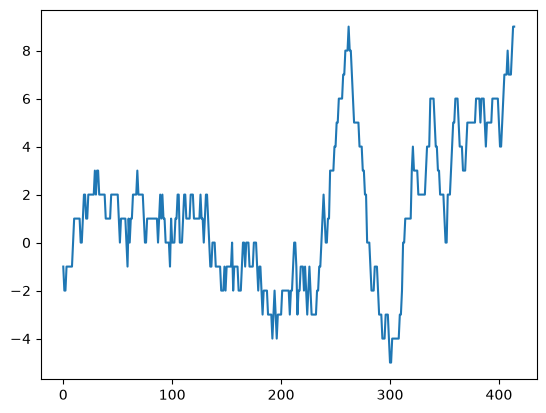

In [25]:
import matplotlib.pyplot as plt
import numpy as np

dusp_sequence = list("MASTHQSSTEPSSTGKSEETKKDASQGSGQDSKNVTVTKGTGSSATSAAIVKTGGSQGKDSSTTAGSSSTQGQKFSTTPTDPKTFSSDQKEKSKSPAKEVPSGGDSKSQGDTKSQSDAKSSGQSQGQSKDSGKSSSDSSKSHSVIGAVKDVVAGAKDVAGKAVEDAPSIMHTAVDAVKNAATTVKDVASSAASTVAEKVVDAYHSVVGDKTDDKKEGEHSGDKKDDSKAGSGSGQGGDNKKSEGETSGQAESSSGNEGAAPAKGRGRGRPPAAAKGVAKGAAKGAAASKGAKSGAESSKGGEQSSGDIEMADASSKGGSDQRDSAATVGEGGASGSEGGAKKGRGRGAGKKADAGDTSAEPPRRSSRLTSSGTGAGSAPAAAKGGAKRAASSSSTPSNAKKQATGGAGKAAATKATAAKSAASKAPQNGAGAKKKGGKAGGRKRK") 
dsup_charge_seq = []

for x in dusp_sequence:
    if x == "R":
        dsup_charge_seq.append(1)
    elif x == "K":
        dsup_charge_seq.append(1)
    elif x == "D":
        dsup_charge_seq.append(-1)
    elif x == "E":
        dsup_charge_seq.append(-1)
    else:
        dsup_charge_seq.append(0)

print(dsup_charge_seq)
print("sequence length:", len(dsup_charge_seq))
print("total positive charge:", dsup_charge_seq.count(1))
print("total negative charge:", dsup_charge_seq.count(-1))
print("total charge:", dsup_charge_seq.count(1) - dsup_charge_seq.count(-1))


# trying some sort of window range that loops through the charges and then plots the total charge in that window to identify charged regions
print(sum(dsup_charge_seq[0:20]))

window_charge = []
window_size = 30

for x in range(len(dsup_charge_seq) - window_size): 
    window = dsup_charge_seq[x : x + window_size]
    window_charge.append(sum(window))


charge_plotable = np.array(window_charge)


plt.plot(charge_plotable)
plt.show()